## Midterm Project
- (a) data exploration & EDA 
- (b) Data Preprocessing and Cleaning
- (c) perform training on different models

In [1]:
import subprocess
gpu = subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout if subprocess.run(['which','nvidia-smi'], capture_output=True).returncode == 0 else ''
print(gpu or 'No Gpu detected: switch the runtime to Gpu before the SVM section training')

No Gpu detected: switch the runtime to Gpu before the SVM section training


In [32]:
import os, gc, re, time, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif



warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',200)
pd.set_option('display.width',200)
sns.set_theme(style='whitegrid', context = 'notebook')
SEED = 42
np.random.seed(SEED)
DATA_DIR = 'home-credit-default-risk' # raw kaggle csvs file location
OUT_DIR = 'home-credit-default-risk/processed' # model-ready arrays written at the end and save to here
os.makedirs(DATA_DIR,exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
blue = '#4C72B0'
orange = '#DD8500'
green = '#55A868'
red = '#C44E52'
#plt.rcParams['axes.grid'] = False

### explanation of imported packages
- os Manage file paths and directories
- gc Garbage collection; helps release unused memory
- re Regular expressions for text processing
- time Measure code execution time
- warnings Control warning messages
- numpy(np) Numerical computation and arrays
- pandas (np) Load, clean, and manimulpate tabular data
- seaborn (sns) Statistical data visualization
- train_test_split Split data into training and test sets
- OneHotEncoder Convert categorical features into numerical columns
- StandardScalar Standardize numercial features

### Data Exploration & Exploratory Data Analysis (EDA)
#### Structure and data types

In [3]:
def load(name, cat=False, **kw):
    """ArithmeticError
    1. read a csv and shrink memory: float64 -> float32, int64 -> int32 (all IDs < 2^31)
    2. optional strings -> category (used for the large auxiliary tables)
    3. **kw means allows a function to accept any number of named keyword arguments
    4. convert float64 -> float32 to save memory
    """
    df = pd.read_csv(f'{DATA_DIR}/{name}.csv', **kw)
    for c in df.columns:
        t = df[c].dtype
        if t == 'float64':
            df[c] = df[c].astype('float32')
        elif t == 'int64':
            df[c] = df[c].astype('int32')
        elif cat and not pd.api.types.is_numeric_dtype(t):
            df[c] = df[c].astype('category')
    return df
def mem(df):
    #total memory usage for the dataset
    return f'{df.memory_usage(deep=True).sum() / 1e6:,.0f} MB'

#### A.1. Structure and data types

In [4]:
"""
assert check that TARGET is the only column present in app_train but not app_test 
app_test is reserved for kaggle score 
"""

app_train = load('application_train')
app_test = load('application_test')

print('application_train: ', app_train.shape, mem(app_train))
print('application_test: ', app_test.shape, mem(app_test))

assert set(app_train.columns) - set(app_test.columns) == {'TARGET'}
assert app_train.SK_ID_CURR.is_unique and app_test.SK_ID_CURR.is_unique

num_cols_raw = app_train.select_dtypes('number').columns.drop(['SK_ID_CURR','TARGET']).tolist()
cat_cols_raw = app_train.select_dtypes(exclude='number').columns.tolist()
flag_cols = [c for c in num_cols_raw if app_train[c].dropna().isin([0,1]).all()]
print(f'{len(num_cols_raw)} numeric columns ({len(flag_cols)} of them are 0/1 flags, {len(cat_cols_raw)} categorical columns)')
display(app_train.head(10)) # present first 10 rows
display(app_train[cat_cols_raw].nunique().sort_values(ascending=False).to_frame('n_levels').T)


application_train:  (307511, 122) 399 MB
application_test:  (48744, 121) 63 MB
104 numeric columns (32 of them are 0/1 flags, 16 categorical columns)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

,ORGANIZATION_TYPE,OCCUPATION_TYPE,NAME_INCOME_TYPE,NAME_TYPE_SUITE,WEEKDAY_APPR_PROCESS_START,WALLSMATERIAL_MODE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,FONDKAPREMONT_MODE,CODE_GENDER,HOUSETYPE_MODE,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,EMERGENCYSTATE_MODE
n_levels,58,18,8,7,7,7,6,6,5,4,3,3,2,2,2,2


#### A.2.Target dalance 
- evaluate 0/1 categorical values ratio in application_train dataset

         count   share
TARGET                
0       282686  0.9193
1        24825  0.0807
Accuracy of always redicting 'repaid':0.919
Imbalance ratio: 11.4 : 1


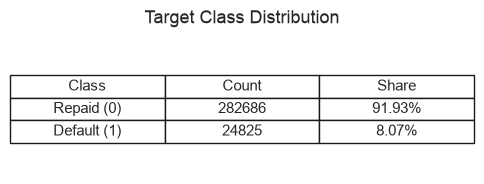

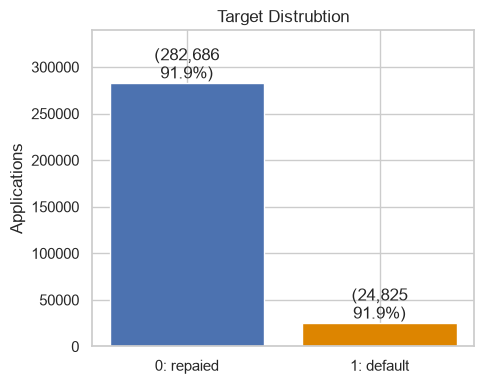

In [5]:
vc = app_train.TARGET.value_counts().sort_index()
print(pd.DataFrame({'count': vc, 'share': (vc/vc.sum()).round(4)}))
print(f'Accuracy of always redicting \'repaid\':{vc[0]/vc.sum():.3f}')
print(f'Imbalance ratio: {vc[0] / vc[1]:.1f} : 1')

#create a table for it
df = pd.DataFrame({
    'Class': ['Repaid (0)','Default (1)'],
    'Count': vc.values,
    'Share': (vc / vc.sum()).map('{:.2%}'.format)
})
accuracy = vc[0] /vc.sum()
imbalance = vc[0] / vc[1]
fig, ax0 = plt.subplots(figsize=(5,2))
ax0.axis('off')

table = ax0.table(
    cellText=df.values.tolist(), # to fix the type error 
    colLabels=df.columns.tolist(),
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1,1.6)
ax0.set_title('Target Class Distribution', fontsize=13, pad=15)
plt.tight_layout()
plt.show()



fig, ax = plt.subplots(figsize=(5,4))
ax.bar(['0: repaied','1: default'], vc.values, color=['#4C72B0','#DD8500'])
for i ,v in enumerate(vc.values):
    ax.text(i, v, f'({v:,}\n{accuracy:.1%})', ha='center', va='bottom')
ax.set_ylabel('Applications'); ax.set_title('Target Distrubtion'); ax.set_ylim(0,vc.max()*1.2)
plt.tight_layout(); 
plt.show()


#### A.3.Missing values evaluation

67 of 122 columns contain missing values: 41 are more than 50% missing ratio.


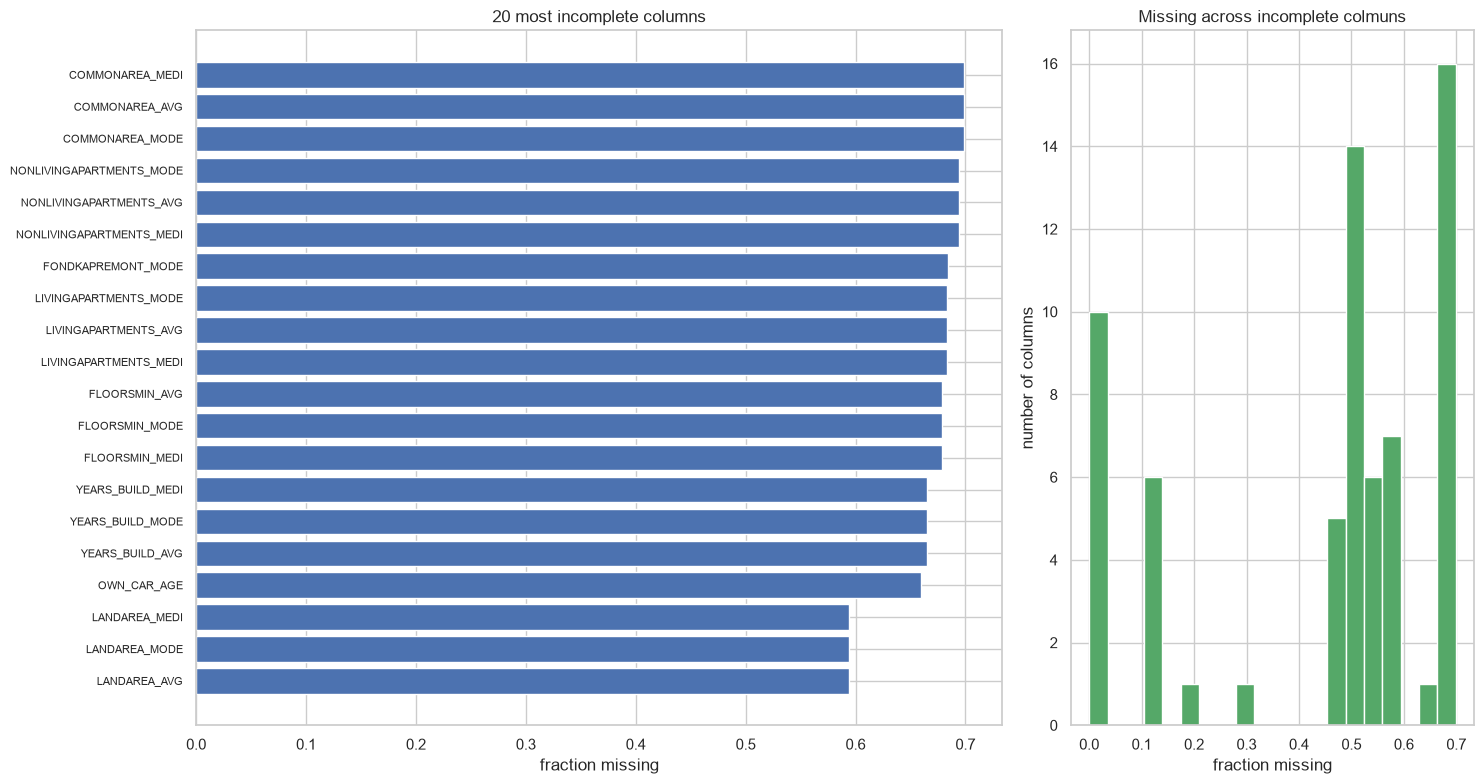

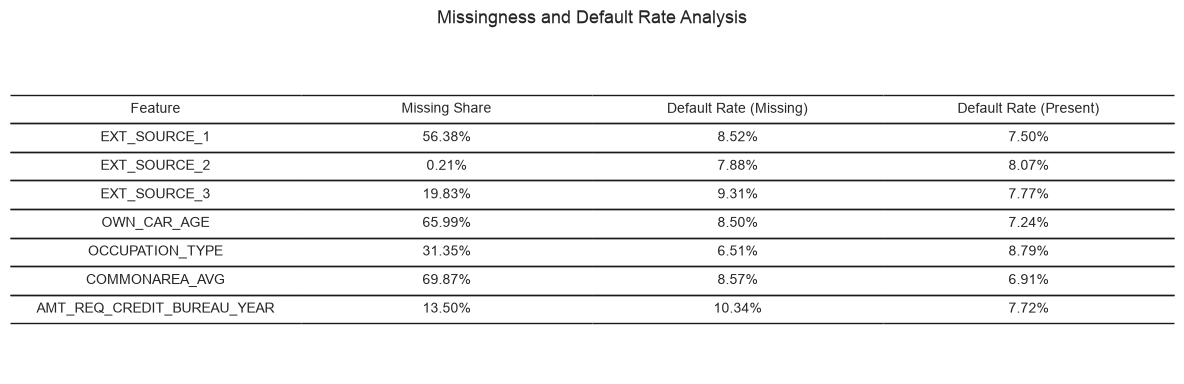

In [6]:
miss = app_train.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f'{len(miss)} of {app_train.shape[1]} columns contain missing values: '
      f'{(miss > 0.5).sum()} are more than 50% missing ratio.'
      ) # 0 is row 1: column

fig, axes = plt.subplots(1,2, figsize = (15,8), gridspec_kw={'width_ratios':[2,1]})
top=miss.head(20)[::-1]
axes[0].barh(top.index, top.values, color=blue)
axes[0].set_xlabel('fraction missing'); axes[0].set_title('20 most incomplete columns')
axes[0].tick_params(axis='y', labelsize=8)
axes[1].hist(miss.values,bins=20, color = green)
axes[1].set_xlabel('fraction missing'); axes[1].set_ylabel('number of columns')
axes[1].set_title('Missing across incomplete colmuns')
plt.tight_layout()
plt.show()


#Compare default rates with and without a value.
check = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'OWN_CAR_AGE', 'OCCUPATION_TYPE',
         'COMMONAREA_AVG', 'AMT_REQ_CREDIT_BUREAU_YEAR']
rows = []
for c in check:
    m = app_train[c].isna()
    rows.append({
        'feature':c,
        'missing_share':m.mean(),
        'default_rate_if_missing':app_train.TARGET[m].mean(),
        'default_rate_if_present':app_train.TARGET[~m].mean()
    })


# Convert to DataFrame
df = pd.DataFrame(rows)

# Format percentages
df_plot = df.copy()
for c in df_plot.columns[1:]:
    df_plot[c] = df_plot[c].map('{:.2%}'.format)

# Create table
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

table = ax.table(
    cellText=df_plot.values.tolist(),
    colLabels=[
        'Feature',
        'Missing Share',
        'Default Rate (Missing)',
        'Default Rate (Present)'
    ],
    loc='center',
    cellLoc='center',
    edges='horizontal'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

ax.set_title('Missingness and Default Rate Analysis',
             fontsize=13, pad=15)

plt.tight_layout()
plt.show()


#### A.4.Statistic summary and anomalies

,count,mean,std,min,1%,50%,99%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.14,25650.00,45000.00,147150.00,472500.00,1.170000e+08
AMT_CREDIT,307511.0,599026.00,402490.78,45000.00,76410.00,513531.00,1854000.00,4.050000e+06
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.50,6182.91,24903.00,70006.50,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.19,369446.47,40500.00,67500.00,450000.00,1800000.00,4.050000e+06
DAYS_BIRTH,307511.0,-16037.00,4363.99,-25229.00,-24419.00,-15750.00,-8263.00,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.05,141275.77,-17912.00,-10894.90,-1213.00,365243.00,3.652430e+05
DAYS_REGISTRATION,307511.0,-4986.12,3522.89,-24672.00,-13879.00,-4504.00,-50.00,0.000000e+00
DAYS_ID_PUBLISH,307511.0,-2994.20,1509.45,-7197.00,-5447.00,-3254.00,-61.00,0.000000e+00
CNT_CHILDREN,307511.0,0.42,0.72,0.00,0.00,0.00,3.00,1.900000e+01
CNT_FAM_MEMBERS,307509.0,2.15,0.91,1.00,1.00,2.00,5.00,2.000000e+01


,Group,Missing %,Mean,Std,Min,P1,Median,P99,Max,Skew
Features,,,,,,,,,,
AMT_INCOME_TOTAL,Monetary,0.0,"168,797.92","237,123.14","25,650.00","45,000.00","147,150.00","472,500.00","117,000,000.00",391.6
AMT_CREDIT,Monetary,0.0,"599,026.00","402,490.78","45,000.00","76,410.00","513,531.00","1,854,000.00","4,050,000.00",1.2
AMT_ANNUITY,Monetary,0.0,"27,108.57","14,493.74","1,615.50","6,182.91","24,903.00","70,006.50","258,025.50",1.6
AMT_GOODS_PRICE,Monetary,0.1,"538,396.19","369,446.47","40,500.00","67,500.00","450,000.00","1,800,000.00","4,050,000.00",1.3
DAYS_BIRTH,Temporal (days before application),0.0,"-16,037.00","4,363.99","-25,229.00","-24,419.00","-15,750.00","-8,263.00","-7,489.00",-0.1
DAYS_EMPLOYED,Temporal (days before application),0.0,"63,815.05","141,275.77","-17,912.00","-10,894.90","-1,213.00","365,243.00","365,243.00",1.7
DAYS_REGISTRATION,Temporal (days before application),0.0,"-4,986.12","3,522.89","-24,672.00","-13,879.00","-4,504.00",-50.00,0.00,-0.6
DAYS_ID_PUBLISH,Temporal (days before application),0.0,"-2,994.20","1,509.45","-7,197.00","-5,447.00","-3,254.00",-61.00,0.00,0.3
CNT_CHILDREN,Household,0.0,0.42,0.72,0.00,0.00,0.00,3.00,19.00,2.0


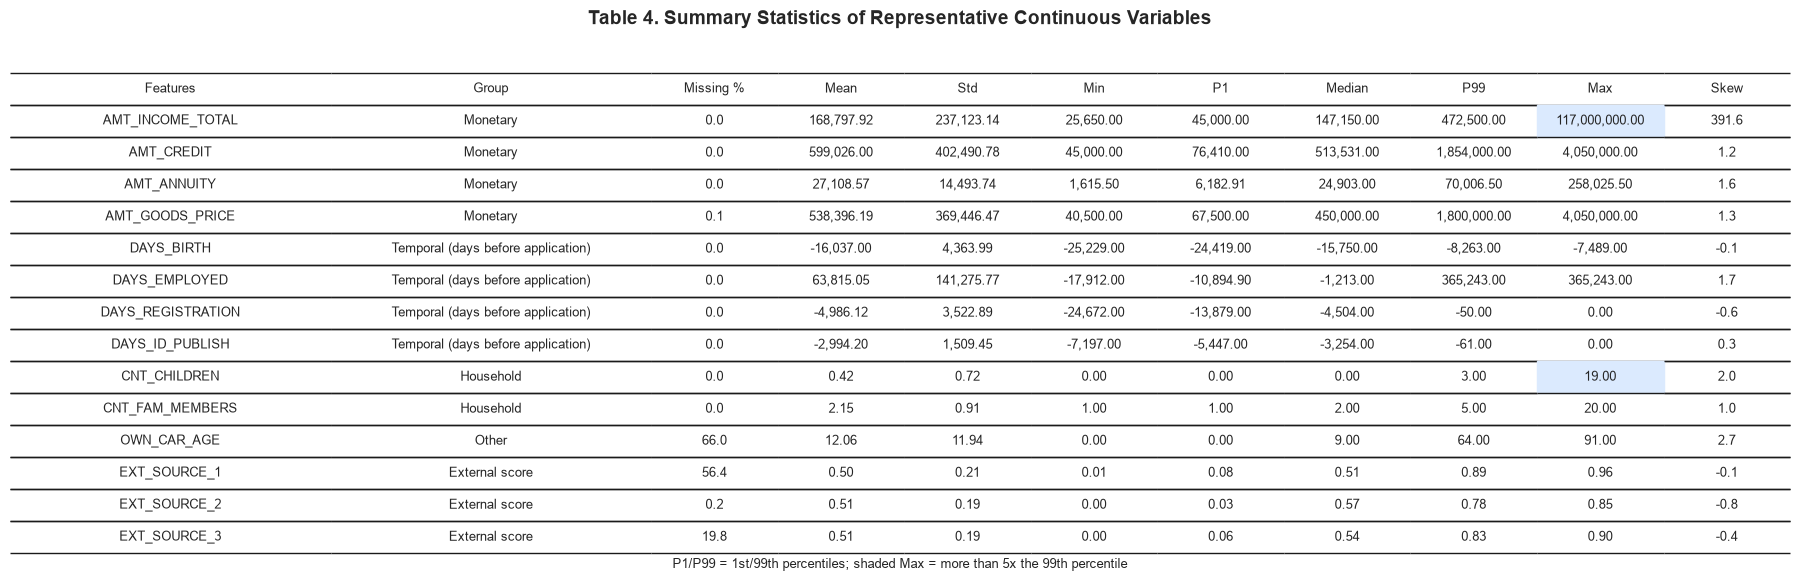

In [7]:
key_features = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
           'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'OWN_CAR_AGE',
           'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
desc = app_train[key_features].describe(percentiles=[0.01,0.5,0.99]).T
display(desc.round(2))

groups = (['Monetary']*4+ ['Temporal (days before application)']*4+['Household']*2+['Other']+['External score']*3)
summary = pd.DataFrame({
    'Group': groups,
    'Missing %': app_train[key_features].isna().mean().mul(100).values,
    'Mean': desc['mean'].values,
    'Std': desc['std'].values,
    'Min': desc['min'].values,
    'P1': desc['1%'].values,
    'Median':desc['50%'].values,
    'P99':desc['99%'].values,
    'Max': desc['max'].values,
    'Skew': app_train[key_features].skew().values
},

index = pd.Index(key_features, name="Features")
)

table4 = (summary.style
          .format('{:,.2f}', subset=['Mean', 'Std', 'Min', 'P1', 'Median', 'P99', 'Max'])
          .format('{:,.1f}', subset=['Missing %', 'Skew'])
          #highlight colmuns where the maxis far beyond the 99th percentile(outliers)
          .apply(lambda r: ['background-color: #dbeafe' if (c == 'Max' and abs(r['Max']) > 5 * abs(r['P99']) and r['P99'] != 0) else ''
                            for c in r.index], axis=1)
        .set_caption('Table 4. Summary statistics of representative continuous variables '
                       '(P1/P99 = 1st/99th percentiles; shaded Max = more than 5x the 99th percentile)')
          .set_table_styles([{'selector': 'caption',
                              'props': 'caption-side: top; font-weight: bold; font-size: 1.05em; text-align: left;'}]))
display(table4)

# Keep feature names as a column
df_plot = summary.reset_index().copy()

# Highlight outliers: Max > 5 × P99
outliers = (
    (summary['P99'] != 0) &
    (summary['Max'].abs() > 5 * summary['P99'].abs())
)

# Format numeric columns
num_cols = ['Mean', 'Std', 'Min', 'P1',
            'Median', 'P99', 'Max']

for c in num_cols:
    df_plot[c] = df_plot[c].map('{:,.2f}'.format)

for c in ['Missing %', 'Skew']:
    df_plot[c] = df_plot[c].map('{:,.1f}'.format)

# Create table
fig, ax = plt.subplots(figsize=(18, 6))
ax.axis('off')
ax.grid(False)

table = ax.table(
    cellText=df_plot.values.tolist(),
    colLabels=df_plot.columns.tolist(),
    loc='center',
    cellLoc='center',
    edges='horizontal'
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.7)

# Highlight Max column for outliers
#max_col = df_plot.columns.get_loc('Max')
max_col = df_plot.columns.tolist().index('Max')

for i, is_outlier in enumerate(outliers):
    if is_outlier:
        #table[(i + 1, max_col)].set_facecolor(	'#dbeafe')
        cell = table[(i+1,max_col)]
        cell.set_facecolor('#dbeafe')
        cell.visible_edges='closed'
        cell.set_edgecolor('#dbeafe')

# Adjust column widths
for i, col in enumerate(df_plot.columns):
    width = 0.19 if col in ['Features', 'Group'] else 0.075

    for row in range(len(df_plot) + 1):
        table[(row, i)].set_width(width)

ax.set_title(
    'Table 4. Summary Statistics of Representative Continuous Variables',
    fontsize=14,
    fontweight='bold',
    pad=20
)

fig.text(
    0.5, 0.04,
    'P1/P99 = 1st/99th percentiles; shaded Max = more than 5x the 99th percentile',
    ha='center',
    fontsize=9
)
plt.tight_layout()
plt.show()

#### A.5.Anomaly Decection and Analysis after statistic summary

DAYS_EMPLOYED == 365243 in 55,374 rows(18.0%)
Default rate: anomalous 0.0540 vs others 0.0866
NAME_INCOME_TYPE anomalous rows: 
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64
test set: 19.0% anomalous


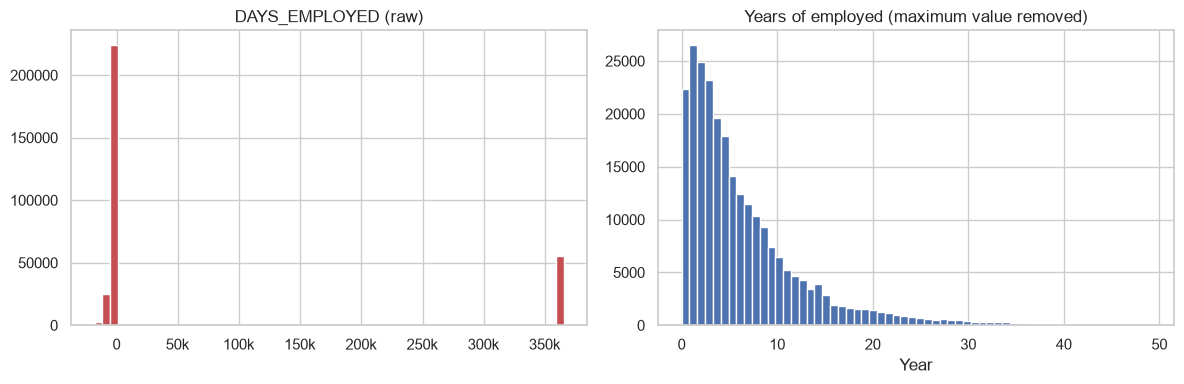


 CODE_GENDER:  {'F': 202448, 'M': 105059, 'XNA': 4}
ORGANIZATION_TYPE=="XNA":  55374 )

Largest incomes:  [117000000, 18000090, 13500000, 9000000, 6750000]
Skewness of monetary columns: 
AMT_INCOME_TOTAL    391.600006
AMT_CREDIT            1.200000
AMT_ANNUITY           1.600000
AMT_GOODS_PRICE       1.300000
dtype: float32


In [43]:
anom = app_train.DAYS_EMPLOYED == 365243
print(f'DAYS_EMPLOYED == 365243 in {anom.sum():,} rows({anom.mean():.1%})') # add thousands separators; add percentage
print(f'Default rate: anomalous {app_train.TARGET[anom].mean():.4f} vs others {app_train.TARGET[~anom].mean():.4f}')
print('NAME_INCOME_TYPE anomalous rows: ');
print(app_train.loc[anom, 'NAME_INCOME_TYPE'].value_counts().head())
print(f'test set: {(app_test.DAYS_EMPLOYED==365243).mean():.1%} anomalous')

fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].hist(app_train.DAYS_EMPLOYED, bins=60, color=red)
# reduce the x-axis scale by x/1000 -> xk
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x/1000:g}k' if x != 0 else '0')
)
axes[0].set_title('DAYS_EMPLOYED (raw)')
axes[1].hist(-app_train.loc[~anom, 'DAYS_EMPLOYED'] / 365, bins=60, color=blue)
axes[1].set_title('Years of employed (maximum value removed)')
axes[1].set_xlabel('Year')
plt.tight_layout()
plt.show()

# amomaly 2 : placeholder categories
print('\n CODE_GENDER: ', app_train.CODE_GENDER.value_counts().to_dict())
print('ORGANIZATION_TYPE=="XNA": ', ((app_train.ORGANIZATION_TYPE=='XNA')& anom).sum(), ')')

#amonaly 3: extreme incomes / heavy tails
print('\nLargest incomes: ', app_train.AMT_INCOME_TOTAL.nlargest(5).astype(int).tolist())
print('Skewness of monetary columns: ')
print(app_train[['AMT_INCOME_TOTAL','AMT_CREDIT','AMT_ANNUITY','AMT_GOODS_PRICE']].skew().round(1))


======================================================================================================
#### A.6.Distrbution by Target
======================================================================================================

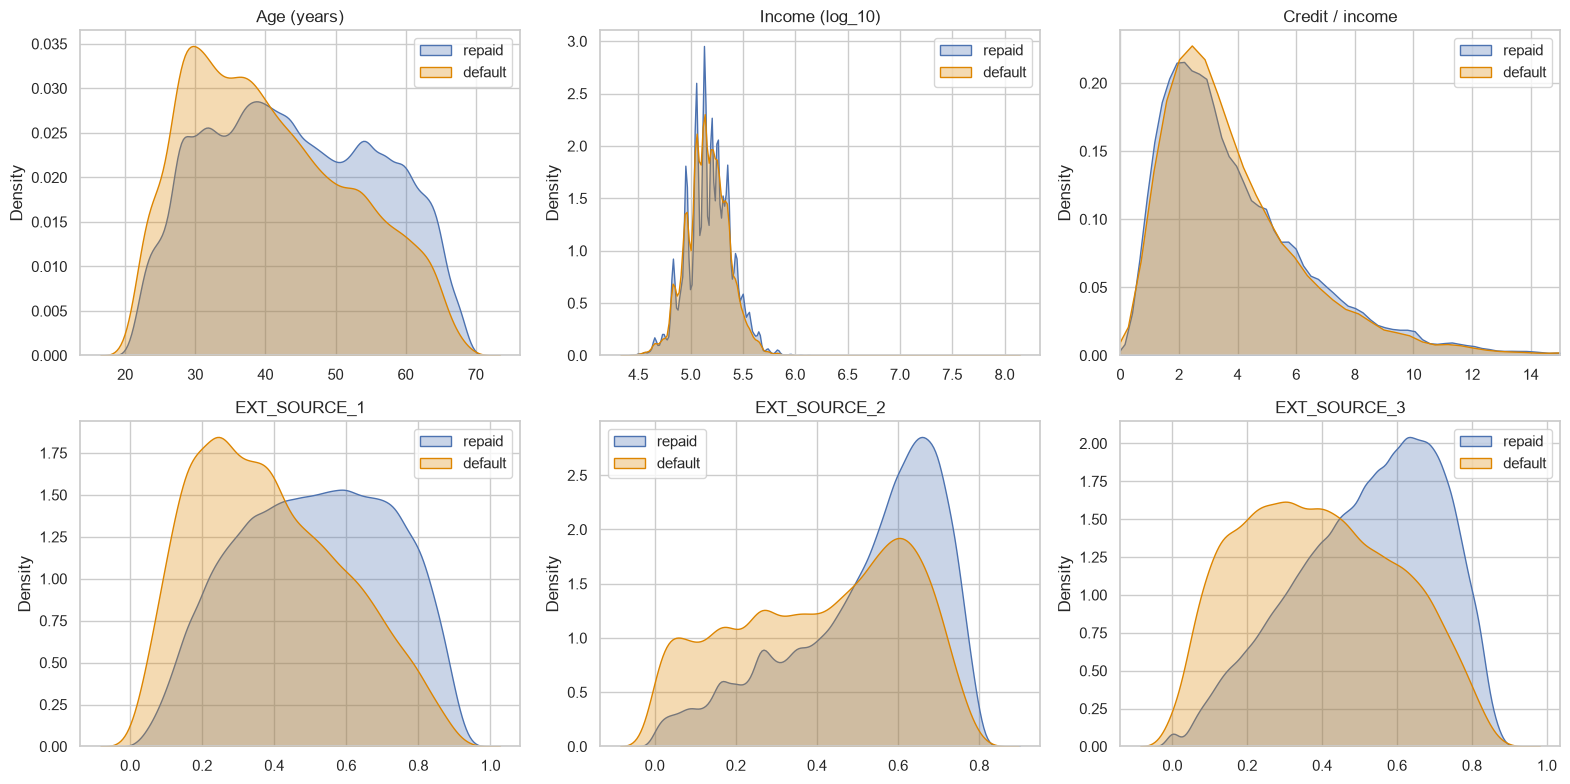

In [ ]:
def kde_by_target(ax, s, title, log=False):
    s = np.log10(s.clip(lower=1)) if log else s
    for t, lab, col in [(0, 'repaid', blue), (1, 'default', orange)]:
        sns.kdeplot(s[app_train.TARGET == t].dropna(), ax=ax, label=lab, color=col, fill=True,
                    alpha=.3, common_norm=False)
    ax.set_title(title); ax.set_xlabel(''); ax.legend()

fig, axes = plt.subplots(2,3,figsize=(16,8))
kde_by_target(axes[0, 0], -app_train.DAYS_BIRTH / 365, 'Age (years)')
kde_by_target(axes[0,1], app_train.AMT_INCOME_TOTAL, 'Income (log_10)', log=True)
kde_by_target(axes[0,2], app_train.AMT_CREDIT / app_train.AMT_INCOME_TOTAL, 'Credit / income')
axes[0,2].set_xlim(0,15)
for i,c in enumerate(['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
    kde_by_target(axes[1,i], app_train[c],c)
plt.tight_layout()
plt.show()


======================================================================================================
#### A.7.Correlation
======================================================================================================

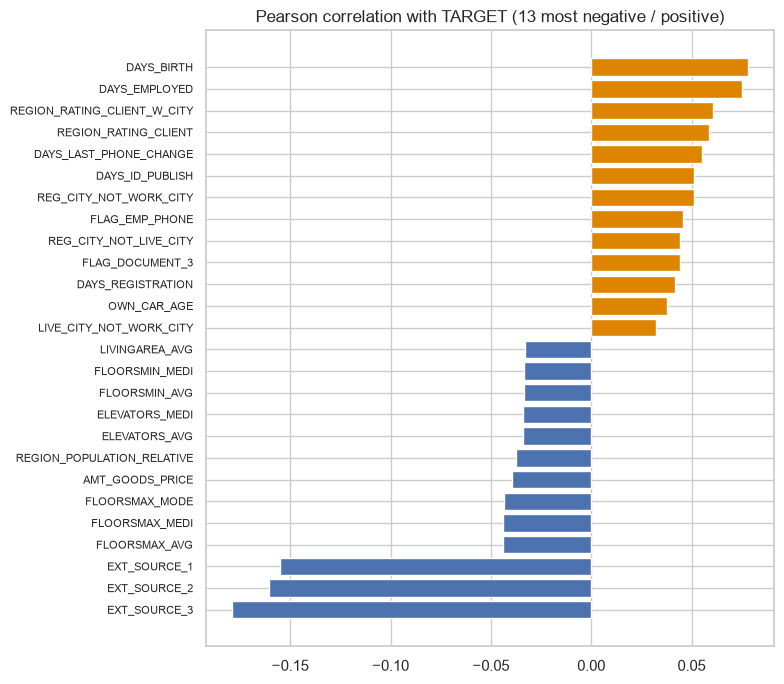

In [44]:
corr_df = app_train.select_dtypes('number').drop(columns=['SK_ID_CURR']).copy() # only select the numerical columns and remove applicant ID
corr_df.loc[corr_df.DAYS_EMPLOYED==365243, 'DAYS_EMPLOYED'] = np.nan # with anomaly of 365243 the value replaces by NaN
corr_t = corr_df.drop(columns='TARGET').corrwith(corr_df.TARGET).dropna().sort_values()

top_corr = pd.concat([corr_t.head(13), corr_t.tail(13)])
fig, ax = plt.subplots(figsize=(8,7))
ax.barh(top_corr.index, top_corr.values,color=np.where(top_corr.values < 0, blue, orange))
ax.set_title('Pearson correlation with TARGET (13 most negative / positive)')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()


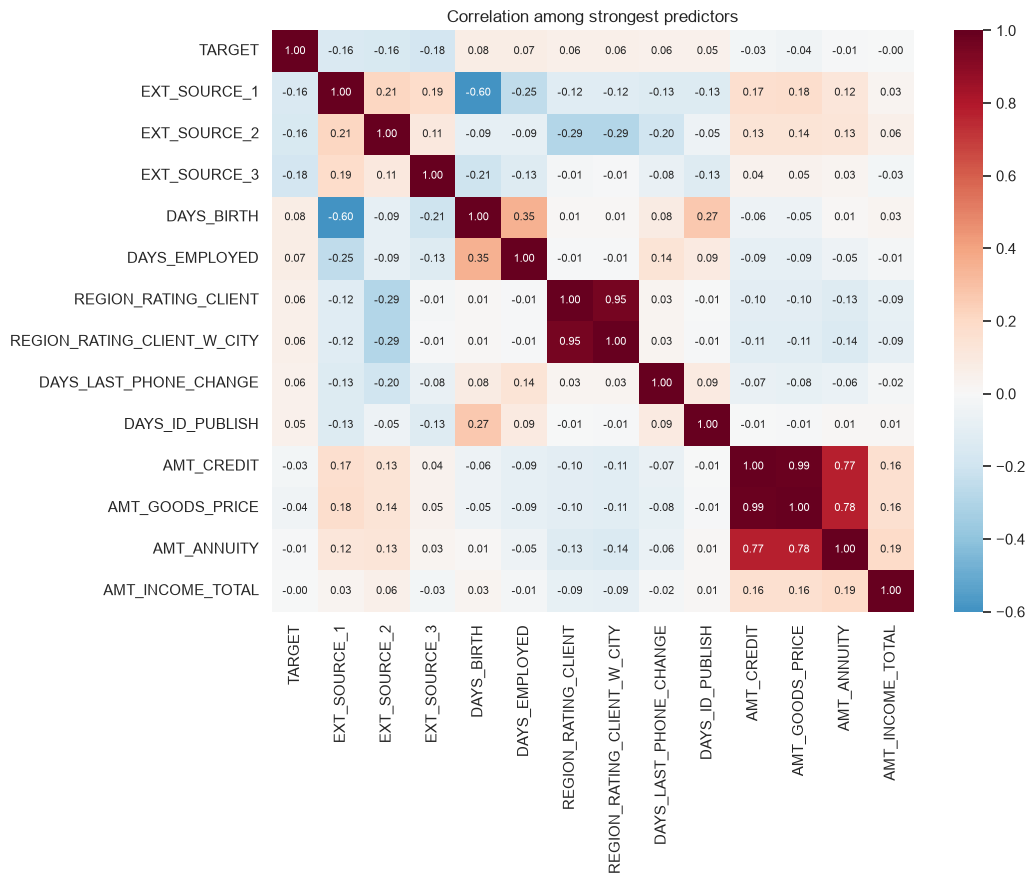

Numeric feature pairs with |r| > 0.95: 45  (mostly the building *_AVG / *_MODE / *_MEDI triplets, plus AMT_CREDIT vs AMT_GOODS_PRICE)


In [29]:
heat_cols = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
             'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'DAYS_LAST_PHONE_CHANGE', 'DAYS_ID_PUBLISH',
             'AMT_CREDIT', 'AMT_GOODS_PRICE', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL']
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_df[heat_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Correlation among strongest predictors'); plt.tight_layout(); plt.show()

# How much redundancy is there among numeric features?
C = corr_df.drop(columns='TARGET').corr().abs().values
iu = np.triu_indices_from(C, k=1)
print(f'Numeric feature pairs with |r| > 0.95: {(C[iu] > 0.95).sum()}  '
      '(mostly the building *_AVG / *_MODE / *_MEDI triplets, plus AMT_CREDIT vs AMT_GOODS_PRICE)')
del corr_df, C; _ = gc.collect()

======================================================================================================
#### A.8.Default rate by Categorical features
- Chooe the top 10 categorical features using mutual information, it may introduce the error, but the choice is based on alogrithm
- $I(X; Y) = H(Y) - H(Y|X)$
- $X$: A categorical feature
- $Y$: the binary targt (TARGET= 0,1)
- $H(Y)$: entropy (uncertainty) of the target before observing the feature.
- $H(Y|X)$: remaining uncertainty about the target after ovserving the feature
- High MI means the feature provides more information about the target

Total categorical features: 16

Top 10 categorical features:
OCCUPATION_TYPE        0.0031
ORGANIZATION_TYPE      0.0027
NAME_INCOME_TYPE       0.0021
NAME_EDUCATION_TYPE    0.0018
CODE_GENDER            0.0015
WALLSMATERIAL_MODE     0.0010
EMERGENCYSTATE_MODE    0.0009
HOUSETYPE_MODE         0.0008
NAME_FAMILY_STATUS     0.0008
NAME_HOUSING_TYPE      0.0006
Name: Mutual Information, dtype: float64


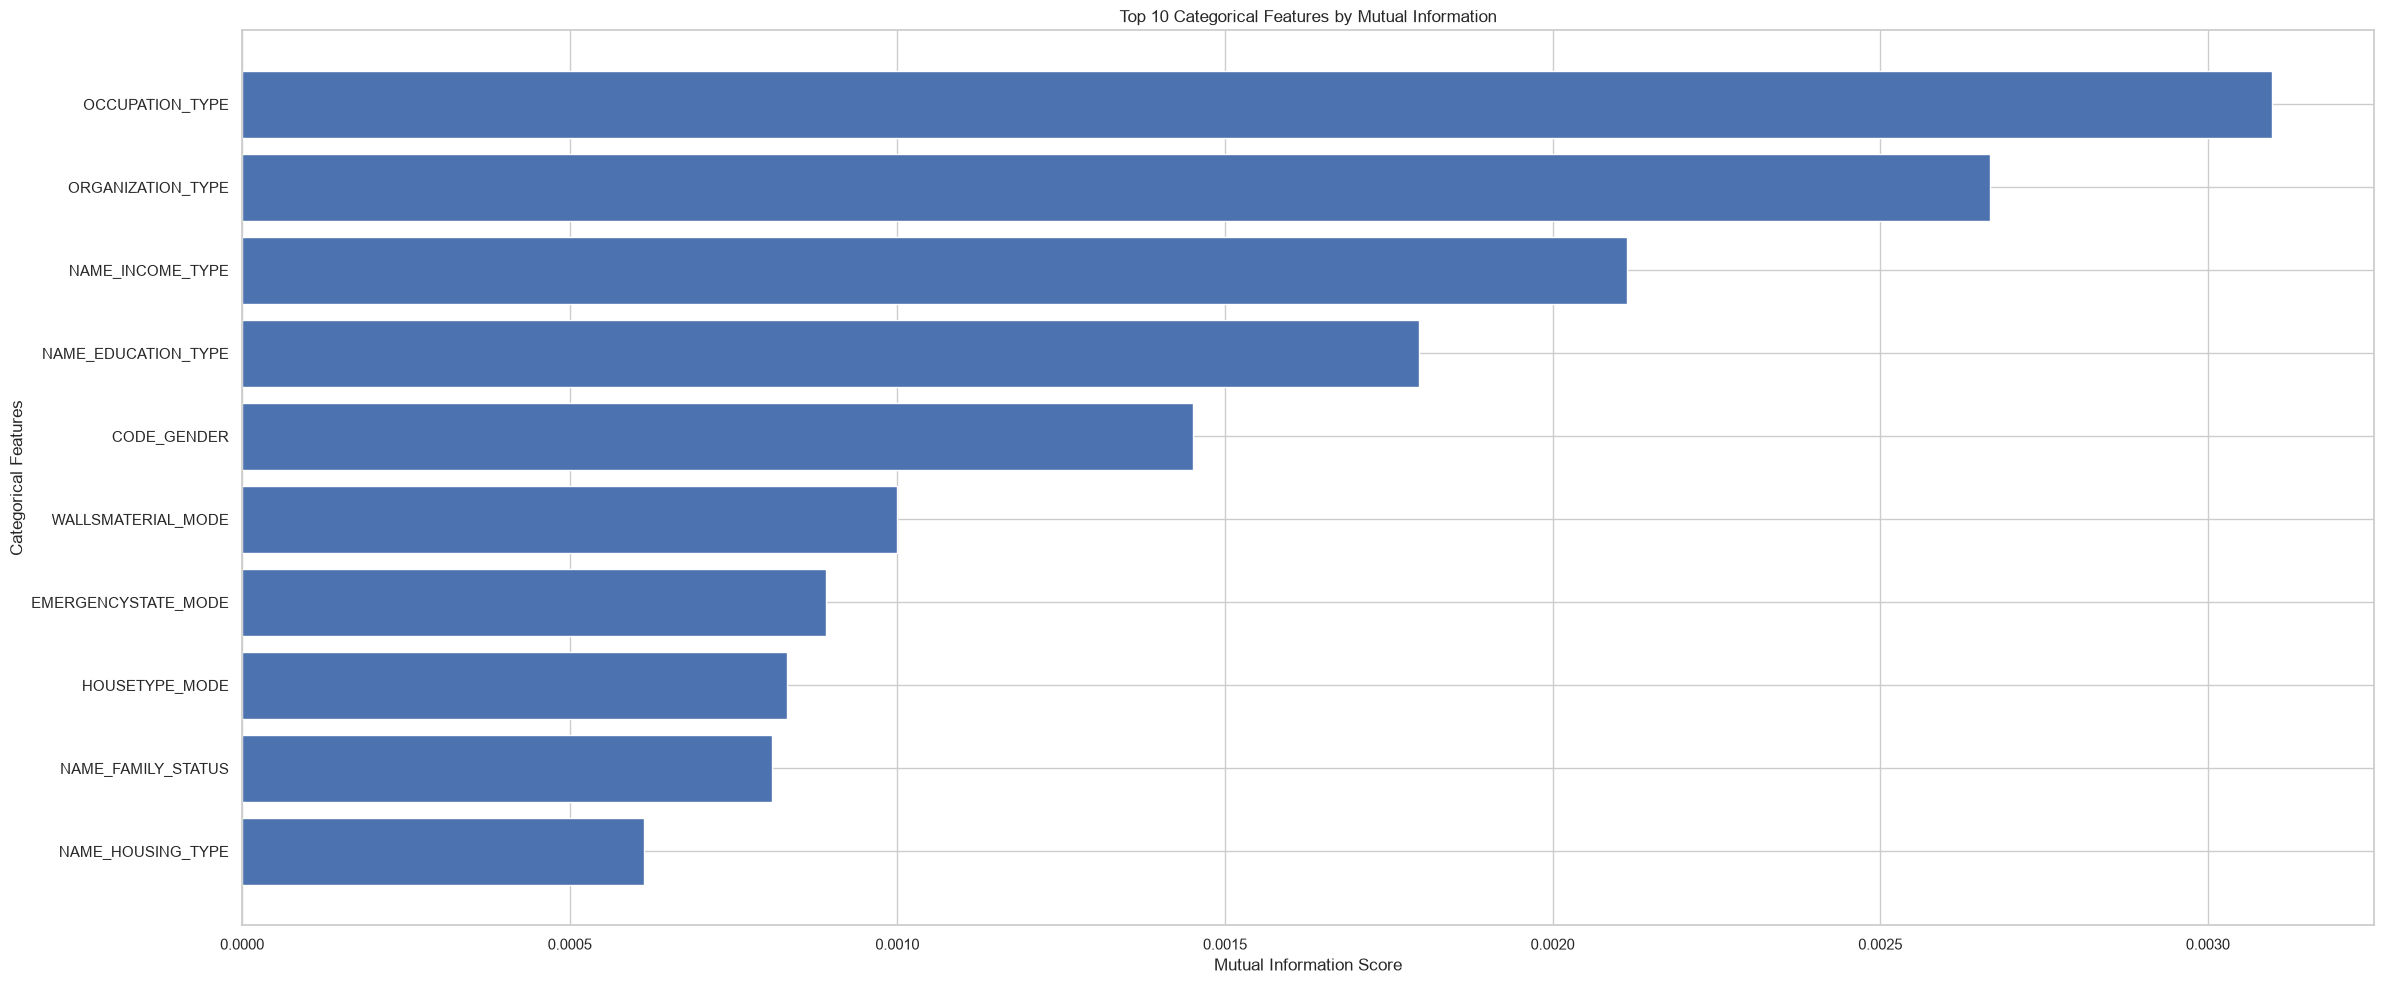

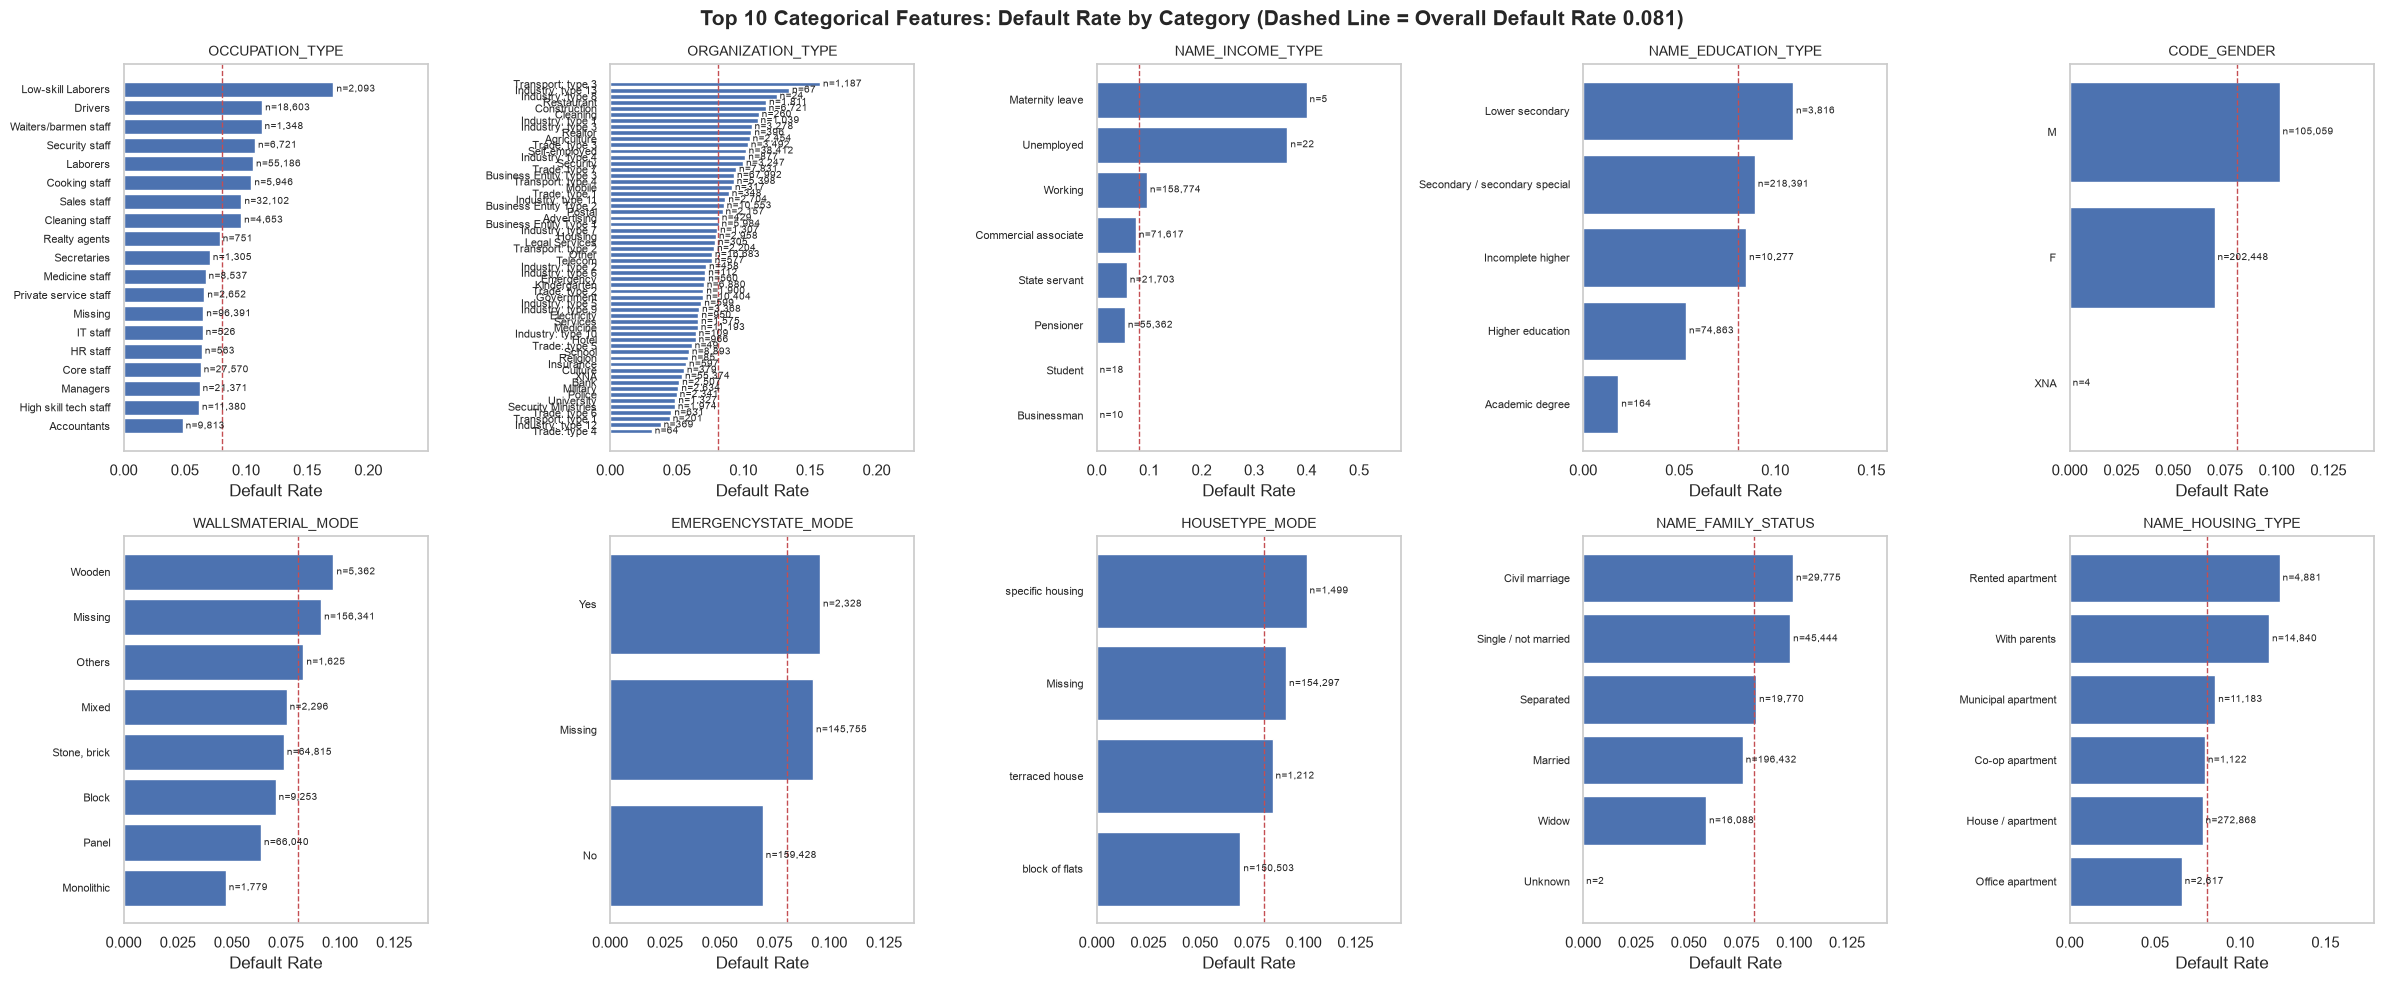

In [ ]:


# 1. Identify categorical features
cat_cols = app_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print(f'Total categorical features: {len(cat_cols)}')

# 2. Prepare categorical data
X_cat = app_train[cat_cols].fillna('Missing').astype(str)
y = app_train['TARGET']

# 3. Encode categorical features as integers
encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_encoded = encoder.fit_transform(X_cat)

# 4. Calculate mutual information scores
mi = mutual_info_classif(
    X_encoded,
    y,
    discrete_features=True,
    random_state=42
)

# 5. Rank all categorical features
mi_scores = pd.Series(
    mi,
    index=cat_cols,
    name='Mutual Information'
).sort_values(ascending=False)

# 6. Automatically select the top 10
cats_plot = mi_scores.head(10).index.tolist()

print('\nTop 10 categorical features:')
print(mi_scores.head(10).round(4))

# 7. Plot top 10 features
top10 = mi_scores.head(10).sort_values()

fig, ax = plt.subplots(figsize=(24, 10))

ax.barh(
    top10.index,
    top10.to_numpy(dtype=float),
    color=blue
)
# the information of MI score is above
ax.set_xlabel('Mutual Information Score')
ax.set_ylabel('Categorical Features')
ax.set_title('Top 10 Categorical Features by Mutual Information')

plt.tight_layout()
plt.show()

# 8. Final selected features
#print('\ncats_plot =', cats_plot)

# use the picked top 10 to do the analysis
# Select top 10 categorical features by mutual information
cats_plot = mi_scores.head(10).index.tolist()

# Overall default rate
base = app_train['TARGET'].mean()

# Create 2 rows × 5 columns
fig, axes = plt.subplots(2, 5, figsize=(24, 10))

for ax, c in zip(axes.ravel(), cats_plot):

    # Calculate default rate and sample count by category
    g = (
        app_train
        .groupby(app_train[c].fillna('Missing'))['TARGET']
        .agg(['mean', 'size'])
        .sort_values('mean')
    )

    # Horizontal bar chart
    ax.barh(
        g.index.astype(str).tolist(),
        g['mean'].to_numpy(dtype=float),
        color='#4C72B0'
    )

    # Display sample counts
    for y, (m, n) in enumerate(g[['mean', 'size']].itertuples(
        index=False, name=None
    )):
        ax.text(
            m, y,
            f' n={int(n):,}',
            va='center',
            fontsize=7
        )

    # Overall default rate reference line
    ax.axvline(base, color='#C44E52', ls='--', lw=1)

    ax.set_title(c, fontsize=10)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_xlabel('Default Rate')

    # Adjust x-axis range
    ax.set_xlim(0, max(g['mean'].max(), base) * 1.45)

    # Remove background grid
    ax.grid(False)

fig.suptitle(
    f'Top 10 Categorical Features: Default Rate by Category '
    f'(Dashed Line = Overall Default Rate {base:.3f})',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


#### A.10.Auxiliary Tables from other tables
- https://www.kaggle.com/code/willkoehrsen/start-here-a-gentle-introduction
- according to the linkage to evaluate other tables information